<a href="https://colab.research.google.com/github/felixxx14/sign-language-digits/blob/main/Projet_signes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip install kaggle -q
!pip install opencv-python-headless -q
import matplotlib.pyplot as plt
import os
from google.colab import userdata

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"]      = userdata.get("KAGGLE_KEY")

import kaggle
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from keras import layers
import cv2
from google.colab import files
import mediapipe as mp

# Téléchargement du dataset
kaggle.api.dataset_download_files(
    "muhammadkhalid/sign-language-for-numbers",
    path="/content",
    unzip=True
)

print("Dataset prêt !")

Dataset URL: https://www.kaggle.com/datasets/muhammadkhalid/sign-language-for-numbers
Dataset prêt !


In [ ]:
# Initialize MediaPipe Hands
mp_hands = mp.solutions.hands
hands = mp_hands.Hands(
    static_image_mode=True,
    max_num_hands=1,
    min_detection_confidence=0.3
)

dataset_path = "/content/Sign Language for Numbers"
label_map_new_dataset = {
    "0": 0, "1": 1, "2": 2, "3": 3, "4": 4,
    "5": 5, "6": 6, "7": 7, "8": 8, "9": 9
}


all_hand_landmarks_data = [] # Stores flattened (x, y, z) coordinates
all_labels = []
all_image_paths = []
images_with_hands = 0
images_without_hands = 0

print("Starting hand landmark extraction from dataset...")

# Iterate through the dataset
for digit_folder_name in os.listdir(dataset_path):
    if digit_folder_name.isdigit(): # Ensure it's a digit folder (0-9)
        current_label = label_map_new_dataset[digit_folder_name]
        folder_path = os.path.join(dataset_path, digit_folder_name)

        for image_filename in os.listdir(folder_path):
            # Process only image files
            if image_filename.lower().endswith(('.jpg', '.jpeg', '.png')):
                img_path = os.path.join(folder_path, image_filename)
                img = cv2.imread(img_path)

                if img is None:
                    print(f"Warning: Could not read image {img_path}. Skipping file processing.")
                    continue

                # Convert the BGR image to RGB for MediaPipe.
                img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

                # Process the image and find hands
                results = hands.process(img_rgb)

                if results.multi_hand_landmarks:
                    # For simplicity, we take the first detected hand
                    hand_landmarks = results.multi_hand_landmarks[0]

                    # Extract x, y, z coordinates for each landmark and flatten them
                    landmarks_flat = []
                    for landmark in hand_landmarks.landmark:
                        # MediaPipe coordinates are normalized to [0.0, 1.0]
                        landmarks_flat.extend([landmark.x, landmark.y, landmark.z])

                    all_hand_landmarks_data.append(landmarks_flat)
                    all_labels.append(current_label)
                    all_image_paths.append(img_path) # Store image path
                    images_with_hands += 1
                else:
                    # Add a row of NaNs for non-detected hands
                    # 21 landmarks * 3 coordinates (x, y, z) = 63 features
                    landmarks_flat_nan = [np.nan] * (21 * 3)
                    all_hand_landmarks_data.append(landmarks_flat_nan)
                    all_labels.append(current_label) # Still append the label
                    all_image_paths.append(img_path) # Store image path even if no hand detected
                    images_without_hands += 1

print(f"Finished processing. Images with hands detected: {images_with_hands}, images without hands (NaNs added): {images_without_hands}")

# Release MediaPipe resources
hands.close()

# Create column names for the DataFrame (21 landmarks * 3 coordinates = 63 features)
landmark_col_names = []
for i in range(21): # 21 landmarks in MediaPipe Hands
    landmark_col_names.extend([f'x_{i}', f'y_{i}', f'z_{i}'])

if all_hand_landmarks_data:
    # Convert to NumPy arrays
    hand_landmarks_array = np.array(all_hand_landmarks_data)
    labels_array = np.array(all_labels)
    image_paths_array = np.array(all_image_paths)

    # Create a Pandas DataFrame
    df_landmarks = pd.DataFrame(hand_landmarks_array, columns=landmark_col_names)
    df_landmarks['label'] = labels_array
    df_landmarks['image_path'] = image_paths_array # Add image path column

    # Save the DataFrame to a CSV file
    output_csv_path = "/content/hand_landmarks_dataset.csv"
    df_landmarks.to_csv(output_csv_path, index=False)
    print(f"\nDataset successfully created and saved to {output_csv_path}")
    print(f"Dataset shape: {df_landmarks.shape} (rows: images, columns: 63 landmark coordinates + 1 label + 1 image_path)")
    print("First 5 rows of the generated dataset:")
    print(df_landmarks.head())
else:
    print("\nNo image data was processed to extract hand landmarks. The dataset could not be created. Please check your image paths and MediaPipe detection configuration.")

Starting hand landmark extraction from dataset...


/usr/local/lib/python3.12/dist-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '
/usr/local/lib/python3.12/dist-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '
/usr/local/lib/python3.12/dist-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


Finished processing. Images with hands detected: 7509, images without hands (NaNs added): 7491

Dataset successfully created and saved to /content/hand_landmarks_dataset.csv
Dataset shape: (15000, 65) (rows: images, columns: 63 landmark coordinates + 1 label + 1 image_path)
First 5 rows of the generated dataset:
        x_0       y_0           z_0       x_1       y_1       z_1       x_2  \
0       NaN       NaN           NaN       NaN       NaN       NaN       NaN   
1       NaN       NaN           NaN       NaN       NaN       NaN       NaN   
2  0.457392  0.816682  7.038740e-07  0.493594  0.752786 -0.040639  0.503930   
3  0.427848  0.813740  7.506827e-07  0.471582  0.760747 -0.042105  0.491416   
4       NaN       NaN           NaN       NaN       NaN       NaN       NaN   

        y_2       z_2       x_3  ...      y_18      z_18      x_19      y_19  \
0       NaN       NaN       NaN  ...       NaN       NaN       NaN       NaN   
1       NaN       NaN       NaN  ...       NaN     

### Construction et entraînement du modèle basé sur les Landmarks (Mediapipe)

In [ ]:
NUM_CLASSES = 10 # 10 classes pour les chiffres 0-9

# Charger les données du dataset de landmarks
df_landmarks = pd.read_csv('/content/hand_landmarks_dataset.csv')

# Supprimer les lignes avec des valeurs NaN (où aucune main n'a été détectée)
df_landmarks_cleaned = df_landmarks.dropna()

# Séparer les caractéristiques (landmarks) et les labels
# S'assurer que 'image_path' est aussi exclu des caractéristiques si présent
columns_to_drop = ['label']
if 'image_path' in df_landmarks_cleaned.columns:
    columns_to_drop.append('image_path')
X_mp = df_landmarks_cleaned.drop(columns_to_drop, axis=1).values
y_mp_int = df_landmarks_cleaned['label'].values # Garder les labels entiers pour train_test_split

# Convertir les labels en one-hot encoding pour le modèle
y_mp_oh = tf.keras.utils.to_categorical(y_mp_int, num_classes=NUM_CLASSES)

# Diviser les données en ensembles d'entraînement et de test
X_train_mp, X_test_mp, y_train_mp_oh, y_test_mp_oh, y_train_mp_int, y_test_mp_int = train_test_split(
    X_mp, y_mp_oh, y_mp_int, test_size=0.2, random_state=42, stratify=y_mp_int
)

print(f"X_train_mp shape: {X_train_mp.shape}")
print(f"y_train_mp_oh shape: {y_train_mp_oh.shape}")
print(f"X_test_mp shape: {X_test_mp.shape}")
print(f"y_test_mp_oh shape: {y_test_mp_oh.shape}")

X_train_mp shape: (6007, 63)
y_train_mp_oh shape: (6007, 10)
X_test_mp shape: (1502, 63)
y_test_mp_oh shape: (1502, 10)


In [ ]:
# Définir l'architecture du modèle pour les données de landmarks
modelmp = keras.Sequential([
    layers.Input(shape=(X_train_mp.shape[1],)), # Input est un vecteur aplati de 63 coordonnées
    layers.Dense(128, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.4), # Increased dropout rate
    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.4), # Increased dropout rate
    layers.Dense(NUM_CLASSES, activation="softmax") # 10 classes pour les chiffres 0-9
], name="landmark_mlp")

modelmp.summary()

Model: "landmark_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_17 (Dense)                │ (None, 128)            │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,866 (69.79 KB)

 Trainable params: 17,482 (68.29 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
# Compiler le modèle
modelmp.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


Epoch 1/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6434 - loss: 1.1776 - val_accuracy: 0.6618 - val_loss: 1.5309
Epoch 2/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8638 - loss: 0.4788 - val_accuracy: 0.9141 - val_loss: 0.5951
Epoch 3/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9028 - loss: 0.3628 - val_accuracy: 0.9241 - val_loss: 0.3100
Epoch 4/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9049 - loss: 0.3379 - val_accuracy: 0.9268 - val_loss: 0.2662
Epoch 5/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9124 - loss: 0.3046 - val_accuracy: 0.8748 - val_loss: 0.4312
Epoch 6/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9179 - loss: 0.2977 - val_accuracy: 0.9394 - val_loss: 0.2247
Epoch 7/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9141 - loss: 0.3022 - val_accuracy: 0.9314 - val_loss: 0.2406
Epoch 8/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9169 - loss: 0.2965 - val_accuracy: 0.

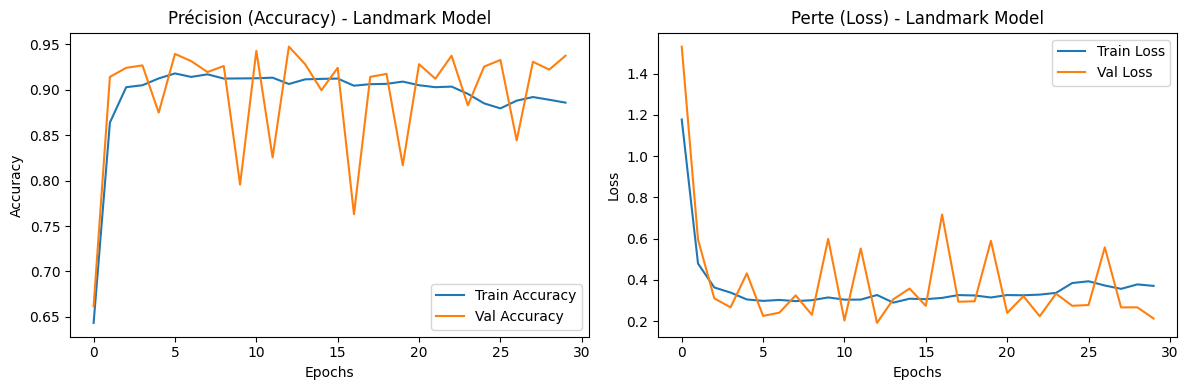

In [ ]:
history_mp = modelmp.fit(
    X_train_mp,
    y_train_mp_oh,
    validation_data=(X_test_mp, y_test_mp_oh),
    epochs=30,
    batch_size=32
)

# Afficher la courbe d'apprentissage
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_mp.history['accuracy'], label='Train Accuracy')
plt.plot(history_mp.history['val_accuracy'], label='Val Accuracy')
plt.title('Précision (Accuracy) - Landmark Model')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_mp.history['loss'], label='Train Loss')
plt.plot(history_mp.history['val_loss'], label='Val Loss')
plt.title('Perte (Loss) - Landmark Model')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Évaluer le modèle sur l'ensemble de test
loss_mp, acc_mp = modelmp.evaluate(X_test_mp, y_test_mp_oh, verbose=0)
print(f"\nAccuracy finale du modèle Landmark : {acc_mp:.1%}")

# Sauvegarder le modèle
modelmp.save("sign_language_landmark_model.keras")



Accuracy finale du modèle Landmark : 93.7%


In [ ]:
import random
import cv2 # Assurez-vous que cv2 est importé
import numpy as np # Assurez-vous que numpy est importé
import matplotlib.pyplot as plt # Assurez-vous que matplotlib.pyplot est importé
import os # Assurez-vous que os est importé
import tensorflow as tf # Assurez-vous que tensorflow est importé

def mp_predict(image_data, display_output=True):
  """
  Predicts the digit(s) in an image using the MediaPipe-based landmark model.
  Handles multiple hands in an image, returning a prediction for each.

  Args:
    image_data (numpy.ndarray): The input image (NumPy array, BGR format).
    display_output (bool): Whether to display the image with landmarks and prediction.

  Returns:
    tuple: (list of dicts containing hand predictions, image_with_annotations)
           Each dict in the list contains:
               'predicted_digit_str': predicted digit,
               'prediction_probabilities': probabilities array,
               'hand_landmarks_flat': flattened landmark coordinates (optional, for debugging)
           If no hand is detected or image cannot be read, the list will be empty.
           image_with_annotations is the image with drawings for display.
  """
  # Recharger le modèle de landmarks si ce n'est pas déjà fait
  try:
      modelmp
  except NameError:
      if display_output: print("Loading modelmp from saved file...")
      modelmp = tf.keras.models.load_model("sign_language_landmark_model.keras")

  # Initialiser MediaPipe Hands (permettant la détection de plusieurs mains)
  mp_hands = mp.solutions.hands
  hands = mp_hands.Hands(
      static_image_mode=True,
      max_num_hands=2, # Allow detecting up to 2 hands as per user request for multiple hands
      min_detection_confidence=0.3
  )
  mp_drawing = mp.solutions.drawing_utils

  original_image = image_data.copy() # Use provided image_data directly, now it's expected to be a numpy array
  if original_image is None:
      if display_output: print(f"Warning: Image data is None. Skipping.")
      hands.close()
      return [], None # Return empty list of predictions and None for image

  # Convertir l'image BGR en RGB pour MediaPipe.
  image_rgb = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)
  image_with_annotations = original_image.copy() # Initialize image to draw on

  # Process the image and find hands
  results = hands.process(image_rgb)

  hand_predictions = []

  if results.multi_hand_landmarks:
      if display_output: print(f"Hands detected on image (ndarray input)")

      # Define a smaller drawing spec for landmarks
      smaller_point_spec = mp_drawing.DrawingSpec(color=(0, 255, 0), thickness=1, circle_radius=1) # Green points, radius 1, thickness 1

      for idx, hand_landmarks in enumerate(results.multi_hand_landmarks):
          mp_drawing.draw_landmarks(
              image_with_annotations, hand_landmarks, mp_hands.HAND_CONNECTIONS,
              landmark_drawing_spec=smaller_point_spec)

          # Extraire les coordonnées x, y, z et les aplatir pour le modèle
          landmarks_flat = []
          for landmark in hand_landmarks.landmark:
              # MediaPipe coordinates are normalized to [0.0, 1.0]
              landmarks_flat.extend([landmark.x, landmark.y, landmark.z])

          landmarks_for_prediction = np.array(landmarks_flat).reshape(1, -1) # Reshape pour l'entrée du modèle

          # Effectuer la prédiction
          prediction_probabilities = modelmp.predict(landmarks_for_prediction, verbose=0) # Suppress verbose output
          predicted_class_index = np.argmax(prediction_probabilities)
          predicted_digit_str = str(predicted_class_index)

          hand_predictions.append({
              'predicted_digit_str': predicted_digit_str,
              'prediction_probabilities': prediction_probabilities,
              'hand_landmarks_flat': landmarks_flat # Optional, for debugging/analysis
          })

          # Add text annotation for each hand (e.g., predicted digit near the wrist)
          wrist_landmark = hand_landmarks.landmark[mp_hands.HandLandmark.WRIST]
          # Convert normalized coordinates to pixel coordinates for drawing text
          x_text = int(wrist_landmark.x * image_with_annotations.shape[1])
          y_text = int(wrist_landmark.y * image_with_annotations.shape[0]) - 20 # Offset text above wrist

          cv2.putText(image_with_annotations, f"Pred: {predicted_digit_str}",
                      (x_text, y_text), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2, cv2.LINE_AA)

      if display_output:
          plt.figure(figsize=(8, 8))
          plt.imshow(cv2.cvtColor(image_with_annotations, cv2.COLOR_BGR2RGB))
          title_text = f"Image with {len(hand_predictions)} Hand(s) Detected (MediaPipe)"
          plt.title(title_text)
          plt.axis("off")
          plt.show()

          for i, pred_info in enumerate(hand_predictions):
              print(f"Hand {i+1} Prediction: {pred_info['predicted_digit_str']}, Probabilities: {pred_info['prediction_probabilities']}")

  else:
      if display_output: print(f"No hand detected on image (ndarray input) by MediaPipe.")

  hands.close()
  return hand_predictions, image_with_annotations

In [ ]:
def random_predict(dataset_path, label_map, num_samples=1):
    """
    Performs random predictions on images from the dataset using the mp_predict function.

    Args:
      dataset_path (str): Path to the dataset.
      label_map (dict): Mapping from digit folder names to integer labels.
      num_samples (int): Number of random samples to predict.

    Returns:
      list: A list of dictionaries, each containing prediction results for a sample.
    """
    print(f"\n--- Test de Prédiction Aléatoire (x{num_samples} images) ---")

    # Collect all image paths and their true labels
    all_image_paths = []
    all_labels = []
    for digit_folder_name in os.listdir(dataset_path):
        if digit_folder_name.isdigit():
            current_label = label_map[digit_folder_name]
            folder_path = os.path.join(dataset_path, digit_folder_name)
            for image_filename in os.listdir(folder_path):
                if image_filename.lower().endswith(('.jpg', '.jpeg', '.png')):
                    all_image_paths.append(os.path.join(folder_path, image_filename))
                    all_labels.append(current_label)

    if not all_image_paths:
        print("Aucune image trouvée dans le dataset spécifié.")
        return

    predictions = []
    for _ in range(num_samples):
        # Select a random image from the collected paths
        idx = np.random.randint(0, len(all_image_paths))
        random_image_path = all_image_paths[idx]
        true_label = all_labels[idx]

        print(f"\nTraitement de l'image aléatoire: {random_image_path} (Vraie étiquette: {true_label})")

        # Use the mp_predict function to process and predict
        hand_detected, predicted_digit_str, prediction_probabilities, image_to_display = mp_predict(random_image_path, display_output=False)

        predicted_digit = None
        if predicted_digit_str != "N/A (main non détectée)":
            predicted_digit = int(predicted_digit_str)

        predictions.append({
            'image_path': random_image_path,
            'true_label': true_label,
            'hand_detected': hand_detected,
            'predicted_digit': predicted_digit,
            'prediction_probabilities': prediction_probabilities
        })

        # Display image with prediction using the returned image_to_display
        plt.figure(figsize=(8, 8))
        plt.imshow(cv2.cvtColor(image_to_display, cv2.COLOR_BGR2RGB))

        title_text = f"Prédiction: {predicted_digit_str} (Réel: {true_label})"
        if not hand_detected:
            title_text = f"Aucune main détectée (Réel: {true_label})"

        plt.title(title_text)
        plt.axis("off")
        plt.show()

        if predicted_digit is not None and prediction_probabilities is not None:
            print(f"Probabilités de prédiction: {prediction_probabilities}")

    return predictions


--- Test de Prédiction Aléatoire (x3 images) ---

Traitement de l'image aléatoire: /content/Sign Language for Numbers/9/nine_1343.jpg (Vraie étiquette: 9)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step


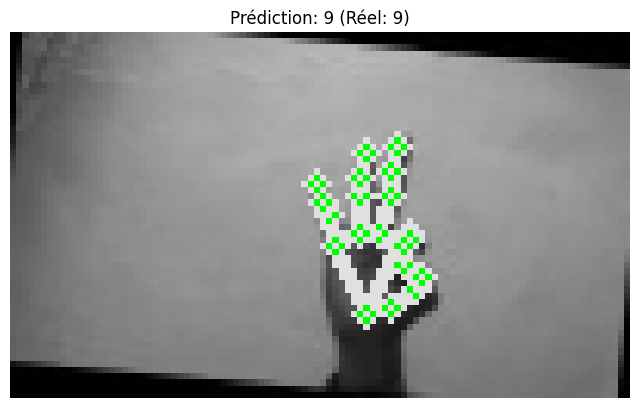

Probabilités de prédiction: [[2.18331385e-02 4.22430321e-06 1.13081485e-04 1.71772239e-03
  8.35973129e-04 1.46737304e-02 3.91235622e-03 1.63373898e-05
  7.21299102e-06 9.56886232e-01]]

Traitement de l'image aléatoire: /content/Sign Language for Numbers/5/five_957.jpg (Vraie étiquette: 5)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step


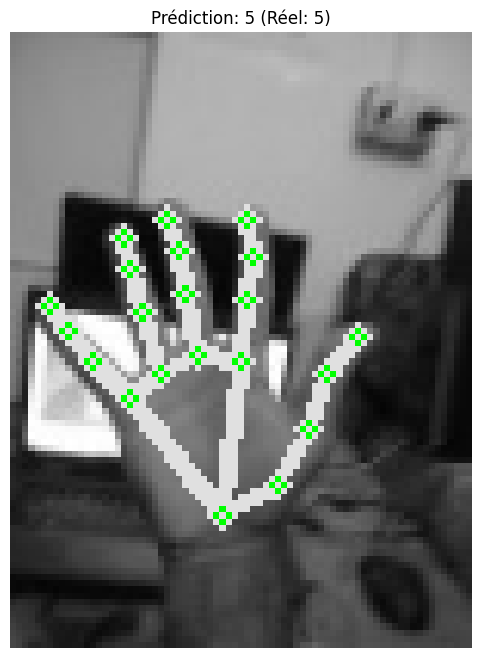

Probabilités de prédiction: [[1.1974674e-07 2.2919193e-10 5.3849453e-10 1.0951555e-05 3.4491978e-07
  9.9998796e-01 8.7041991e-09 5.9680200e-10 6.6575687e-09 6.2213581e-07]]

Traitement de l'image aléatoire: /content/Sign Language for Numbers/7/seven_826.jpg (Vraie étiquette: 7)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step


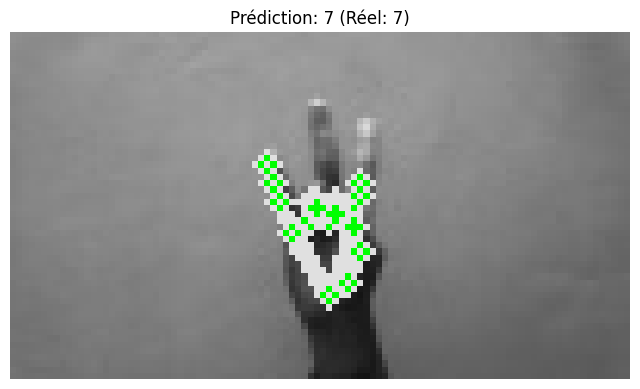

Probabilités de prédiction: [[0.19637929 0.00824662 0.00226473 0.00586603 0.02548973 0.00280669
  0.01093598 0.65824366 0.08648739 0.00327983]]


In [ ]:
dataset_path = "/content/Sign Language for Numbers"
label_map = {"0": 0, "1": 1, "2": 2, "3": 3, "4": 4, "5": 5, "6": 6, "7": 7, "8": 8, "9": 9}

# Perform random predictions
results = random_predict(dataset_path, label_map, num_samples=3)

In [ ]:
image_data = []
labels = []
image_paths_original = [] # New list to store original image paths
IMG_SIZE = 64 # Les images sont de 64x64 dans ce dataset

dataset_path = "/content/Sign Language for Numbers"

# Mapping des noms de dossiers aux chiffres
label_map_new_dataset = {
    "0": 0, "1": 1, "2": 2, "3": 3, "4": 4,
    "5": 5, "6": 6, "7": 7, "8": 8, "9": 9
}

# Parcourir les dossiers et charger les images
for digit_folder in os.listdir(dataset_path):
    if digit_folder.isdigit(): # S'assurer que le dossier est un chiffre
        label = label_map_new_dataset[digit_folder]
        folder_path = os.path.join(dataset_path, digit_folder)
        for image_file in os.listdir(folder_path):
            if image_file.endswith(('.jpg', '.jpeg', '.png')):
                img_path = os.path.join(folder_path, image_file)
                img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE) # Charger en niveaux de gris
                if img is not None:
                    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE)) # Redimensionner à IMG_SIZE
                    image_data.append(img)
                    labels.append(label)
                    image_paths_original.append(img_path) # Store the path

X = np.array(image_data)
Y = np.array(labels)

# Convertir les labels en one-hot encoding
Y_one_hot = tf.keras.utils.to_categorical(Y, num_classes=10)

# Prétraitement : Normaliser les pixels entre 0 et 1
X = X.astype("float32") / 255.0

# Redimensionner X pour correspondre au format d'entrée du modèle (28, 28, 1)
# Les images sont 64x64, nous devons les redimensionner pour le modèle actuel (28x28)
X_resized = np.array([cv2.resize(img, (28, 28), interpolation=cv2.INTER_AREA) for img in X])
X = X_resized.reshape(-1, 28, 28, 1)

# Diviser les données en ensembles d'entraînement et de test, y compris les chemins des images.
X_train, X_test, y_train_oh, y_test_oh, X_train_paths, X_test_paths = train_test_split(
    X, Y_one_hot, image_paths_original, test_size=0.2, random_state=42
)

# Pour l'affichage des labels réels dans la cellule de prédiction, nous avons besoin des labels entiers.
y_train_labels_int = np.argmax(y_train_oh, axis=1) # Labels entiers (ex: 0, 1, 2)
y_test_labels_int = np.argmax(y_test_oh, axis=1)   # Labels entiers (ex: 0, 1, 2)

print(f"X_train shape: {X_train.shape}")
print(f"y_train_oh shape: {y_train_oh.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test_oh shape: {y_test_oh.shape}")
print(f"X_train_paths count: {len(X_train_paths)}")
print(f"X_test_paths count: {len(X_test_paths)}")

X_train shape: (12000, 28, 28, 1)
y_train_oh shape: (12000, 10)
X_test shape: (3000, 28, 28, 1)
y_test_oh shape: (3000, 10)
X_train_paths count: 12000
X_test_paths count: 3000


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Créer un générateur d'images avec augmentation de données moins agressive
datagen = ImageDataGenerator(
    rotation_range=10,          # Rotation aléatoire de 10 degrés (au lieu de 20)
    width_shift_range=0.1,      # Déplacement horizontal aléatoire de 10% (au lieu de 15%)
    height_shift_range=0.1,     # Déplacement vertical aléatoire de 10% (au lieu de 15%)
    shear_range=0.1,            # Cisaillement aléatoire de 10% (au lieu de 15%)
    zoom_range=0.1,             # Zoom aléatoire de 10% (au lieu de 15%)
    horizontal_flip=False,      # Désactiver le retournement horizontal pour les chiffres
    fill_mode='nearest'         # Stratégie pour remplir les pixels nouvellement créés
)

# Préparer le générateur pour les données d'entraînement
datagen.fit(X_train)

print("Data augmentation configurée avec rotation_range=10, width_shift_range=0.1, height_shift_range=0.1, shear_range=0.1, zoom_range=0.1, horizontal_flip=False.")

# Note: Pour utiliser ce générateur, vous devrez modifier la fonction model.fit() dans la cellule suivante
# pour qu'elle utilise `datagen.flow(X_train, y_train_oh, batch_size=64)` au lieu de `X_train, y_train_oh`.

Data augmentation configurée avec rotation_range=10, width_shift_range=0.1, height_shift_range=0.1, shear_range=0.1, zoom_range=0.1, horizontal_flip=False.


In [ ]:
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.GlobalAveragePooling2D(),

    layers.Dense(256, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(NUM_CLASSES, activation="softmax")
], name="sign_cnn")


In [ ]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

Epoch 1/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 40s 177ms/step - accuracy: 0.4303 - loss: 1.6579 - val_accuracy: 0.1047 - val_loss: 5.9826
Epoch 2/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 40s 173ms/step - accuracy: 0.7122 - loss: 0.8697 - val_accuracy: 0.0987 - val_loss: 14.3151
Epoch 3/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 35s 186ms/step - accuracy: 0.8331 - loss: 0.5248 - val_accuracy: 0.3253 - val_loss: 4.6459
Epoch 4/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 34s 179ms/step - accuracy: 0.8847 - loss: 0.3671 - val_accuracy: 0.7230 - val_loss: 0.8539
Epoch 5/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 34s 180ms/step - accuracy: 0.9148 - loss: 0.2727 - val_accuracy: 0.8423 - val_loss: 0.4816
Epoch 6/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 33s 177ms/step - accuracy: 0.9304 - loss: 0.2200 - val_accuracy: 0.7440 - val_loss: 1.0973
Epoch 7/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 35s 185ms/step - accuracy: 0.9426 - loss: 0.1806 - val_accuracy: 0.8277 - val_loss: 0.5414
Epoch 8/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 34s 183ms/step - accuracy: 0.9503 - loss: 

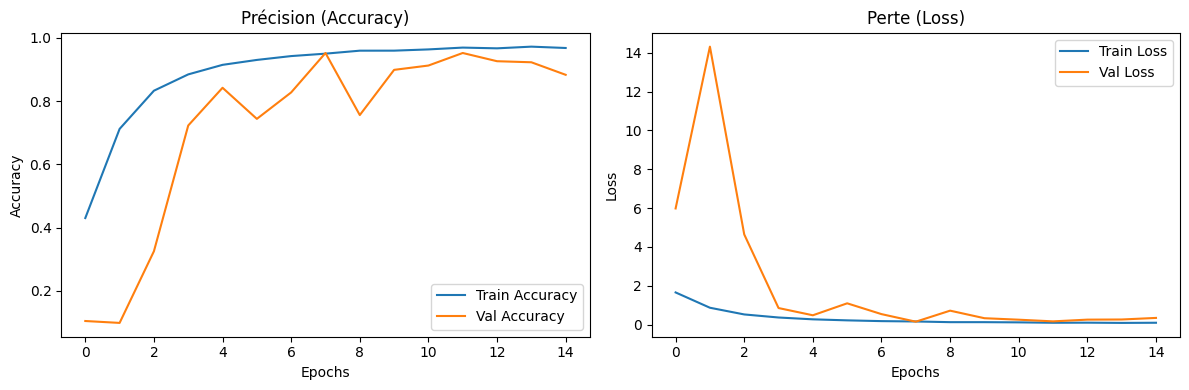

In [ ]:
history = model.fit(
    datagen.flow(X_train, y_train_oh, batch_size=64), # Utiliser le générateur de données augmentées
    validation_data=(X_test, y_test_oh),
    epochs=15,
    batch_size=32
)

# Code pour afficher la courbe d'apprentissage
plt.figure(figsize=(12, 4))

# Courbe de précision (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Précision (Accuracy)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Courbe de perte (Loss)
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Perte (Loss)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
loss, acc = model.evaluate(X_test, y_test_oh, verbose=0)
print(f"\nAccuracy finale : {acc:.1%}")

model.save("sign_language_model.keras")


Accuracy finale : 88.3%


X_test and y_test_oh are already defined.
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step


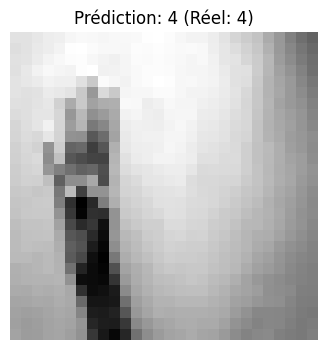

Probabilités de prédiction: [[3.2816038e-03 5.5782525e-06 1.2938624e-04 2.0414277e-06 9.4394535e-01
  4.1669632e-06 5.1141694e-02 4.4756653e-04 2.9544957e-04 7.4723968e-04]]


In [ ]:

NUM_CLASSES = 10 # Should be 10 for digits 0-9

try:
    # Check if X_test and y_test_oh are already defined to avoid redundant operations
    _ = X_test
    _ = y_test_oh
    print("X_test and y_test_oh are already defined.")
except NameError:
    print("X_test or y_test_oh not found. Re-initializing test data.")
    # This block for reading CSV is now irrelevant as we are using .npy for digits
    pass


label_map = {i: str(i) for i in range(NUM_CLASSES)} # Adjust label map for digits 0-9

# Select a random image from the test set for prediction
idx = np.random.randint(0, len(X_test))
sample_image = X_test[idx]
true_label = y_test_labels_int[idx] # Use y_test_labels_int for the true numerical label

# Preprocess the image for the model
# The model expects a batch of images, so add a batch dimension
# It's already 28x28x1 and normalized from previous steps.
input_image_for_model = np.expand_dims(sample_image, axis=0)

# Make a prediction
prediction_probabilities = model.predict(input_image_for_model)
predicted_class_index = np.argmax(prediction_probabilities)

# Get the predicted letter and true letter
predicted_letter = label_map.get(predicted_class_index, f"Unknown ({predicted_class_index})")
true_letter_str = label_map.get(true_label, f"Unknown ({true_label})") # Use the integer true_label

# Display the image and prediction
plt.figure(figsize=(4, 4))
plt.imshow(sample_image.squeeze(), cmap="gray")
plt.title(f"Prédiction: {predicted_letter} (Réel: {true_letter_str})")
plt.axis("off")
plt.show()

print(f"Probabilités de prédiction: {prediction_probabilities}")


In [ ]:
def preprocess_image(image_bgr, display_output=True):
  """
  Preprocesses an input image for the CNN model. Steps include:
  1. Converting to grayscale.
  2. Automatically cropping the hand using MediaPipe (if detected).
  3. Resizing the image to 28x28 pixels.
  4. Normalizing pixel values and reshaping for model input.

  Args:
    image_bgr (numpy.ndarray): The input image (BGR format, 0-255 scale).
    display_output (bool): Whether to display intermediate processing images.

  Returns:
    numpy.ndarray: The processed image ready for model prediction (shape: (1, 28, 28, 1)).
  """

  # Convertir l'image en niveaux de gris
  gray_image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

  if display_output:
      # Afficher l'image originale et en niveaux de gris
      plt.figure(figsize=(10, 5))
      plt.subplot(1, 2, 1)
      plt.imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
      plt.title("Image Originale")
      plt.axis("off")

      plt.subplot(1, 2, 2)
      plt.imshow(gray_image, cmap="gray")
      plt.title("Image en Niveaux de Gris")
      plt.axis("off")
      plt.show()

      print("\n### Rogner la main automatiquement avec MediaPipe ###")

  # 3. Rogner la main avec MediaPipe
  from mediapipe.python.solutions.hands import Hands

  hands_detector = Hands(
      static_image_mode=True,
      max_num_hands=1,
      min_detection_confidence=0.3 # Ajusté pour une détection plus agressive
  )

  # Convertir en RGB pour MediaPipe
  image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
  results = hands_detector.process(image_rgb)

  x_min, y_min = gray_image.shape[1], gray_image.shape[0]
  x_max, y_max = 0, 0
  cropped_image = gray_image  # Par défaut : image complète si aucune main détectée

  if results.multi_hand_landmarks:
      # Extract landmarks and calculate bounding box
      hand_points = []
      for hand_landmarks in results.multi_hand_landmarks:
          for landmark in hand_landmarks.landmark:
              x = int(landmark.x * image_bgr.shape[1])
              y = int(landmark.y * image_bgr.shape[0])
              hand_points.append((x, y))
              x_min = min(x_min, x)
              y_min = min(y_min, y)
              x_max = max(x_max, x)
              y_max = max(y_max, y)

      # Convert hand_points to a numpy array for cv2.convexHull
      hand_points_np = np.array(hand_points, dtype=np.int32)

      # Add padding around the bounding box
      padding = 20
      x_min = max(0, x_min - padding)
      y_min = max(0, y_min - padding)
      x_max = min(image_bgr.shape[1], x_max + padding)
      y_max = min(image_bgr.shape[0], y_max + padding)

      crop_width = x_max - x_min
      crop_height = y_max - y_min

      if crop_width > 0 and crop_height > 0:
          # Crop the original grayscale image directly to the bounding box
          cropped_image = gray_image[y_min:y_max, x_min:x_max]
          if display_output: print(f"Rognage détecté (image rognée directement) : x_min={x_min}, y_min={y_min}, width={crop_width}, height={crop_height}")
      else:
          if display_output: print("Zone de rognage invalide, utilisation de l'image complète.")
  else:
      if display_output: print("Aucune main détectée, utilisation de l'image en niveaux de gris d'origine.")

  hands_detector.close()

  # Vérifier que l'image rognée n'est pas vide
  if cropped_image.shape[0] == 0 or cropped_image.shape[1] == 0:
      if display_output: print("Image rognée vide, utilisation de l'image d'origine.")
      cropped_image = gray_image

  # 4. Redimensionner à 28x28 pixels
  processed_image = cv2.resize(cropped_image, (28, 28), interpolation=cv2.INTER_AREA)

  # 5. Normaliser et remodeler pour le modèle
  processed_image = processed_image.astype("float32") / 255.0
  processed_image = np.expand_dims(processed_image, axis=-1)  # (28, 28, 1)
  processed_image = np.expand_dims(processed_image, axis=0)   # (1, 28, 28, 1)

  if display_output:
      # Afficher l'image traitée
      plt.figure(figsize=(4, 4))
      plt.imshow(processed_image.squeeze(), cmap="gray")
      plt.title("Image Traitée (28x28) pour le Modèle")
      plt.axis("off")
      plt.show()
  return processed_image

In [ ]:
def impredict(image_path, display_output=True):
    """
    Performs image prediction using a hybrid approach: first attempts MediaPipe-based prediction.
    If MediaPipe detects hands, both MediaPipe and the classical CNN model predictions are performed.
    If MediaPipe does not detect hands, it falls back to the classical CNN model only.
    Handles multiple hands in an image for MediaPipe.

    Args:
      image_path (str): The path to the input image file.
      display_output (bool): Whether to display the output images and predictions.

    Returns:
      tuple: (dict containing predictions from both models, image_for_display)
             The dict has keys 'mediapipe_predictions' (list of dicts, can be empty)
             and 'cnn_prediction' (dict or None if no CNN prediction was made).
             Each prediction dict contains 'predicted_digit_str' and 'prediction_probabilities'.
             image_for_display is the annotated image from MediaPipe (if hands detected by MP),
             or the original image (if only CNN was used).
             If image cannot be read, returns ({}, None).
    """
    global model # Declare global model at the beginning of the function

    all_results = {
        'mediapipe_predictions': [],
        'cnn_prediction': None
    }
    image_for_display = None

    original_image = cv2.imread(image_path) # Load image here
    if original_image is None:
        if display_output: print(f"Warning: Could not read image {image_path}. Returning empty results.")
        return all_results, None

    # --- MediaPipe Prediction Attempt ---
    # mp_predict now expects image data (NumPy array), so pass original_image
    mp_predictions_list, image_with_annotations_mp = mp_predict(original_image.copy(), display_output=False) # Pass the array

    if mp_predictions_list: # If MediaPipe detected hands
        all_results['mediapipe_predictions'] = mp_predictions_list
        image_for_display = image_with_annotations_mp # Use MP annotated image for overall display

        if display_output:
            print(f"Prédiction(s) avec MediaPipe : {len(mp_predictions_list)} main(s) détectée(s).")
            # Display the image with landmarks and predictions from MediaPipe
            plt.figure(figsize=(8, 8))
            plt.imshow(cv2.cvtColor(image_with_annotations_mp, cv2.COLOR_BGR2RGB))
            plt.title(f"Image avec Landmarks - Prédiction(s) MediaPipe")
            plt.axis("off")
            plt.show()

            for i, pred_info in enumerate(mp_predictions_list):
                print(f"Main {i+1} MediaPipe Prédiction: {pred_info['predicted_digit_str']} (Probabilités: {pred_info['prediction_probabilities']})")

        # --- ALSO RUN THE CLASSICAL CNN MODEL when MediaPipe detects hands ---
        if display_output: print("\nExécution du modèle CNN classique pour une prédiction complémentaire...")

        # preprocess_image now takes original_image (NumPy array) and display_output
        processed_image_for_cnn = preprocess_image(original_image.copy(), display_output=display_output)

        # Load classical model if not already loaded
        try:
            model # Access model to trigger NameError if not defined
        except NameError:
            if display_output: print("Loading classical model from saved file...")
            model = tf.keras.models.load_model("sign_language_model.keras")

        prediction_probabilities_cnn = model.predict(processed_image_for_cnn, verbose=0) # Suppress verbose output
        predicted_class_index_cnn = np.argmax(prediction_probabilities_cnn)
        predicted_digit_str_cnn = str(predicted_class_index_cnn)

        single_cnn_prediction = {
            'predicted_digit_str': predicted_digit_str_cnn,
            'prediction_probabilities': prediction_probabilities_cnn
        }
        all_results['cnn_prediction'] = single_cnn_prediction
        if display_output: print(f"Prédiction avec modèle classique (CNN) : {predicted_digit_str_cnn} (Probabilités: {prediction_probabilities_cnn})")

        if display_output:
            plt.figure(figsize=(8, 8))
            # Display the original image again for context of the CNN prediction
            plt.imshow(cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB))
            plt.title(f"Prédiction avec modèle classique (CNN): {predicted_digit_str_cnn}")
            plt.axis("off")
            plt.show()

    else:
        # No hand detected by mp_predict. Fallback to classical CNN model only.
        if display_output: print("Aucune main détectée par MediaPipe. Utilisation de preprocess_image et du modèle classique.")

        # preprocess_image now takes original_image (NumPy array) and display_output
        processed_image_for_cnn = preprocess_image(original_image.copy(), display_output=display_output)

        # Load classical model if not already loaded
        try:
            model # Access model to trigger NameError if not defined
        except NameError:
            if display_output: print("Loading classical model from saved file...")
            model = tf.keras.models.load_model("sign_language_model.keras")

        # Perform prediction with the classical model
        prediction_probabilities_cnn = model.predict(processed_image_for_cnn, verbose=0)
        predicted_class_index_cnn = np.argmax(prediction_probabilities_cnn)
        predicted_digit_str_cnn = str(predicted_class_index_cnn)

        single_cnn_prediction = {
            'predicted_digit_str': predicted_digit_str_cnn,
            'prediction_probabilities': prediction_probabilities_cnn
        }
        all_results['cnn_prediction'] = single_cnn_prediction
        if display_output: print(f"Prédiction avec modèle classique : {predicted_digit_str_cnn} (Probabilités: {prediction_probabilities_cnn})")

        # For CNN fallback, use the original image for display.
        image_for_display = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)

        if display_output:
            plt.figure(figsize=(8, 8))
            plt.imshow(image_for_display)
            plt.title(f"Prédiction avec modèle classique: {predicted_digit_str_cnn}")
            plt.axis("off")
            plt.show()

    return all_results, image_for_display

Prédiction(s) avec MediaPipe : 1 main(s) détectée(s).


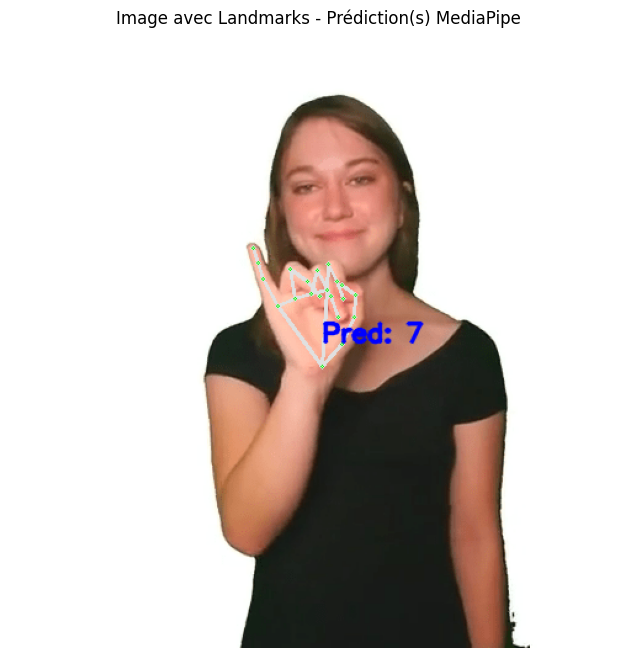

Main 1 MediaPipe Prédiction: 7 (Probabilités: [[2.7894761e-02 3.4819804e-02 8.2079455e-04 8.4365316e-04 9.7770942e-04
  6.5837725e-04 3.6143401e-04 4.8445407e-01 4.4780585e-01 1.3634973e-03]])

Exécution du modèle CNN classique pour une prédiction complémentaire...


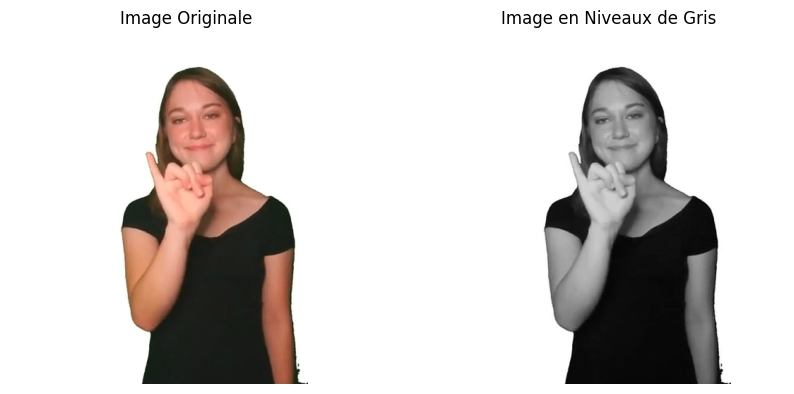


### Rogner la main automatiquement avec MediaPipe ###
Rognage détecté (image rognée directement) : x_min=177, y_min=155, width=123, height=136


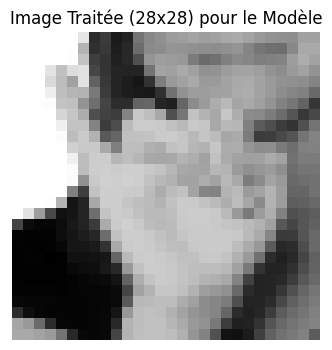

Prédiction avec modèle classique (CNN) : 9 (Probabilités: [[0.00687004 0.22753508 0.02178284 0.00814902 0.13495892 0.00135717
  0.02003095 0.00544916 0.06007678 0.5137901 ]])


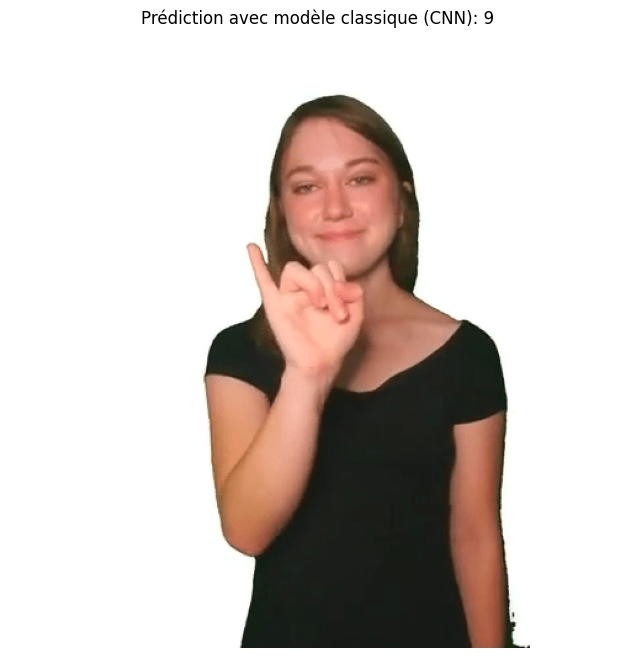


--- Récapitulatif des Prédictions ---
Prédictions MediaPipe :
  Main 1: Prédiction: 7
    Probabilités: [[2.7894761e-02 3.4819804e-02 8.2079455e-04 8.4365316e-04 9.7770942e-04
  6.5837725e-04 3.6143401e-04 4.8445407e-01 4.4780585e-01 1.3634973e-03]]

Prédiction CNN Classique :
  Prédiction: 9
    Probabilités: [[0.00687004 0.22753508 0.02178284 0.00814902 0.13495892 0.00135717
  0.02003095 0.00544916 0.06007678 0.5137901 ]]

Prédiction Finale (Max Somme des Probas) :
  Chiffre Prédit: 9
  Probabilités Combinées: [0.0347648  0.26235489 0.02260364 0.00899267 0.13593663 0.00201555
 0.02039239 0.48990323 0.50788263 0.51515357]


In [ ]:
image_path = "/content/i.png"

# Effectuer la prédiction à l'aide de la fonction impredict
all_predictions_dict, image_with_annotations = impredict(image_path)

# Obtenir la lettre prédite
# Assurez-vous que NUM_CLASSES est défini et correspond au nombre de chiffres (0-9)
# Laisser la redéfinition de label_map pour les chiffres si elle n'est pas déjà faite
if 'label_map' not in locals() or label_map is None or not all(isinstance(v, str) and v.isdigit() for v in label_map.values()):
    NUM_CLASSES = 10 # 10 pour les chiffres 0-9
    label_map = {i: str(i) for i in range(NUM_CLASSES)}

print("\n--- Récapitulatif des Prédictions ---")

mediapipe_preds = all_predictions_dict.get('mediapipe_predictions', [])
cnn_pred = all_predictions_dict.get('cnn_prediction', None)

combined_probabilities = np.zeros(NUM_CLASSES)

if mediapipe_preds:
    print("Prédictions MediaPipe :")
    for i, pred_info in enumerate(mediapipe_preds):
        predicted_class_index = int(pred_info['predicted_digit_str'])
        predicted_letter = label_map.get(predicted_class_index, f"Inconnu ({predicted_class_index})")
        print(f"  Main {i+1}: Prédiction: {predicted_letter}")
        print(f"    Probabilités: {pred_info['prediction_probabilities']}")
        if pred_info['prediction_probabilities'] is not None:
            combined_probabilities += pred_info['prediction_probabilities'].flatten()

if cnn_pred:
    print("\nPrédiction CNN Classique :")
    predicted_class_index = int(cnn_pred['predicted_digit_str'])
    predicted_letter = label_map.get(predicted_class_index, f"Inconnu ({predicted_class_index})")
    print(f"  Prédiction: {predicted_letter}")
    print(f"    Probabilités: {cnn_pred['prediction_probabilities']}")
    if cnn_pred['prediction_probabilities'] is not None:
        combined_probabilities += cnn_pred['prediction_probabilities'].flatten()

# Calcul de la prédiction finale (max de la somme des probabilités)
if np.sum(combined_probabilities) > 0: # Ensure there are probabilities to sum
    final_predicted_class_index = np.argmax(combined_probabilities)
    final_predicted_letter = label_map.get(final_predicted_class_index, f"Inconnu ({final_predicted_class_index})")
    print("\nPrédiction Finale (Max Somme des Probas) :")
    print(f"  Chiffre Prédit: {final_predicted_letter}")
    print(f"  Probabilités Combinées: {combined_probabilities}")
else:
    print("\nAucune prédiction n'a pu être faite par les deux modèles.")


In [ ]:
def final_test(X_test_paths, y_test_labels_int, display_intermediate_output=False):
    """
    Evaluates the hybrid model (MediaPipe + CNN) on the test dataset.
    Leverages pre-computed MediaPipe landmarks from a CSV to avoid recalculation.

    Args:
        X_test_paths (list): List of file paths for the test images.
        y_test_labels_int (np.ndarray): Array of true integer labels for the test images.
        display_intermediate_output (bool): Whether to display images and verbose output for each prediction.

    Returns:
        float: The overall accuracy of the hybrid model on the test set.
    """
    global modelmp # Declare global here
    global model # Declare global here

    correct_predictions = 0
    total_predictions = len(X_test_paths)

    print(f"\n--- Évaluation du Modèle Hybride sur {total_predictions} images de test ---")

    # --- Préparation des Landmarks MediaPipe pré-calculés ---
    # NOTE IMPORTANTE: Pour que cette optimisation fonctionne, le fichier
    # 'hand_landmarks_dataset.csv' DOIT contenir une colonne 'image_path'
    # qui correspond aux chemins d'images dans X_test_paths. Cette colonne
    # doit être ajoutée lors de la création du CSV (cellule F5f2xnMV0vVA).
    # Pour l'instant, nous chargeons le CSV tel quel et gérons l'absence de 'image_path'.

    df_full_landmarks = pd.read_csv('/content/hand_landmarks_dataset.csv')

    # Tentative de créer un mapping si 'image_path' existe (ce qui est nécessaire pour l'optimisation)
    landmarks_lookup = {}
    if 'image_path' in df_full_landmarks.columns:
        # Set 'image_path' as index, then drop 'label' to get only landmark data
        landmarks_df_indexed = df_full_landmarks.set_index('image_path').drop(columns=['label'])
        # Convert to a dictionary where keys are image paths and values are landmark arrays
        landmarks_lookup = {path: row.values.astype(np.float32) for path, row in landmarks_df_indexed.iterrows()}
        print("Mapping des landmarks créé à partir du CSV (colonne 'image_path' détectée).")
    else:
        print("AVERTISSEMENT: La colonne 'image_path' est manquante dans 'hand_landmarks_dataset.csv'.")
        print("MediaPipe sera recalculé pour chaque image car les landmarks pré-calculés ne peuvent pas être associés.")
        print("Veuillez modifier la cellule F5f2xnMV0vVA pour inclure 'image_path' dans le CSV.")

    # --- Boucle d'évaluation ---
    for i, image_path in enumerate(X_test_paths):
        true_label = y_test_labels_int[i]

        if display_intermediate_output:
            print(f"\nTraitement de l'image {i+1}/{total_predictions}: {image_path} (Vraie étiquette: {true_label})")

        # Initialiser les prédictions pour cette image
        mediapipe_preds = []
        cnn_pred = None

        # --- MediaPipe Prediction (using pre-computed landmarks if available) ---
        if image_path in landmarks_lookup:
            precomputed_landmarks = landmarks_lookup[image_path]
            # If landmarks are all NaNs (no hand detected originally)
            if np.all(np.isnan(precomputed_landmarks)):
                if display_intermediate_output: print("  (MediaPipe: Aucune main détectée initialement dans le CSV)")
            else:
                # Reshape for model input and predict with modelmp
                landmarks_for_prediction = precomputed_landmarks[~np.isnan(precomputed_landmarks)].reshape(1, -1)

                # Load modelmp if not already loaded
                try:
                    modelmp
                except NameError:
                    if display_intermediate_output: print("Loading modelmp from saved file...")
                    modelmp = tf.keras.models.load_model("sign_language_landmark_model.keras")

                mp_prediction_probabilities = modelmp.predict(landmarks_for_prediction, verbose=0)
                mp_predicted_class_index = np.argmax(mp_prediction_probabilities)

                mediapipe_preds.append({
                    'predicted_digit_str': str(mp_predicted_class_index),
                    'prediction_probabilities': mp_prediction_probabilities
                })
                if display_intermediate_output:
                    print(f"  (MediaPipe: Prédiction à partir des landmarks CSV: {mp_predicted_class_index})")
        else:
            # Fallback to impredict if image_path not found in lookup (e.g., CSV not updated)
            # This means MediaPipe landmarks WILL be recalculated
            if display_intermediate_output: print("  (MediaPipe: Recalcul des landmarks via impredict - CSV non mappé ou image absente)")
            # This path is kept for compatibility if CSV is not updated, but it recalculates
            all_predictions_dict_from_impredict, _ = impredict(image_path, display_output=False)
            mediapipe_preds = all_predictions_dict_from_impredict.get('mediapipe_predictions', [])
            cnn_pred = all_predictions_dict_from_impredict.get('cnn_prediction', None) # impredict also gives CNN pred

        # --- CNN Prediction (always needs to load and preprocess the image) ---
        # If cnn_pred was already obtained from impredict fallback, use it.
        # Otherwise, compute it separately.
        if cnn_pred is None:
            original_image = cv2.imread(image_path)
            if original_image is not None:
                processed_image_for_cnn = preprocess_image(original_image.copy(), display_output=display_intermediate_output)

                # Load classical model if not already loaded
                try:
                    model # Access model to trigger NameError if not defined
                except NameError:
                    if display_intermediate_output: print("Loading classical model from saved file...")
                    model = tf.keras.models.load_model("sign_language_model.keras")

                prediction_probabilities_cnn = model.predict(processed_image_for_cnn, verbose=0)
                predicted_class_index_cnn = np.argmax(prediction_probabilities_cnn)
                cnn_pred = {
                    'predicted_digit_str': str(predicted_class_index_cnn),
                    'prediction_probabilities': prediction_probabilities_cnn
                }
                if display_intermediate_output:
                    print(f"  (CNN: Prédiction à partir de l'image: {predicted_class_index_cnn})")
            else:
                if display_intermediate_output: print(f"  AVERTISSEMENT: Impossible de lire l'image pour CNN : {image_path}")


        # --- Combinaison des prédictions ---
        combined_probabilities = np.zeros(NUM_CLASSES)
        prediction_made = False

        if mediapipe_preds:
            for pred_info in mediapipe_preds:
                if pred_info['prediction_probabilities'] is not None:
                    combined_probabilities += pred_info['prediction_probabilities'].flatten()
                    prediction_made = True

        if cnn_pred and cnn_pred['prediction_probabilities'] is not None:
            combined_probabilities += cnn_pred['prediction_probabilities'].flatten()
            prediction_made = True

        predicted_digit = -1 # Default to -1 if no prediction could be made
        if prediction_made and np.sum(combined_probabilities) > 0:
            final_predicted_class_index = np.argmax(combined_probabilities)
            predicted_digit = final_predicted_class_index

        if display_intermediate_output:
            print(f"  Prédiction Finale pour {image_path}: {predicted_digit} (Réel: {true_label})")

        if predicted_digit == true_label:
            correct_predictions += 1

    accuracy = correct_predictions / total_predictions
    print(f"\nAccuracy finale du modèle hybride sur l'ensemble de test : {accuracy:.2%}")
    return accuracy

# Exécuter l'évaluation finale
hybrid_model_accuracy = final_test(X_test_paths, y_test_labels_int, display_intermediate_output=False)


--- Évaluation du Modèle Hybride sur 3000 images de test ---
Mapping des landmarks créé à partir du CSV (colonne 'image_path' détectée).


/usr/local/lib/python3.12/dist-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '



Accuracy finale du modèle hybride sur l'ensemble de test : 93.63%
